In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_csv("DS_Day01_50_HR_Overworked_Teams.csv")

In [4]:
print(df.head())

  Team_ID  Project_Hours  Employee_Count  Overtime  Leave  Deadlines  \
0     T06            990              23        58     13          8   
1     T11           1756              31       184     21         13   
2     T05           1362              31        74      4         11   
3     T05           1283              31        32     11         12   
4     T04            520              11        79      2         10   

   Project_Delivery  Satisfaction_Score  
0              95.5                 7.9  
1              83.9                 6.3  
2              96.0                 7.7  
3              89.5                 8.5  
4              90.9                 7.6  


In [5]:
print(df.shape)

(600, 8)


In [6]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 8 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Team_ID             600 non-null    object 
 1   Project_Hours       600 non-null    int64  
 2   Employee_Count      600 non-null    int64  
 3   Overtime            600 non-null    int64  
 4   Leave               600 non-null    int64  
 5   Deadlines           600 non-null    int64  
 6   Project_Delivery    600 non-null    float64
 7   Satisfaction_Score  600 non-null    float64
dtypes: float64(2), int64(5), object(1)
memory usage: 37.6+ KB
None


In [7]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [8]:
print(df.describe())

       Project_Hours  Employee_Count    Overtime       Leave   Deadlines  \
count     600.000000      600.000000  600.000000  600.000000  600.000000   
mean      889.765000       22.520000   50.933333   11.223333    6.931667   
std       362.758187        7.829758   45.607444    4.644287    3.291665   
min       220.000000        9.000000    0.000000    1.000000    1.000000   
25%       625.250000       15.000000   11.750000    8.000000    5.000000   
50%       859.500000       25.000000   42.000000   11.000000    7.000000   
75%      1142.750000       29.000000   76.250000   15.000000    9.000000   
max      1971.000000       35.000000  202.000000   23.000000   19.000000   

       Project_Delivery  Satisfaction_Score  
count        600.000000          600.000000  
mean          93.288167            8.498333  
std            4.805861            0.890704  
min           74.800000            5.200000  
25%           90.400000            7.900000  
50%           93.900000            8.60

In [9]:
df["Project_Hours"].mean()

np.float64(889.765)

In [10]:
df["Overtime"].mean()

np.float64(50.93333333333333)

In [11]:
df["Satisfaction_Score"].mean()

np.float64(8.498333333333333)

In [12]:
df["Workload_Per_Employee"] = (
    df["Project_Hours"] / df["Employee_Count"]
)

In [13]:
print(df.head())

  Team_ID  Project_Hours  Employee_Count  Overtime  Leave  Deadlines  \
0     T06            990              23        58     13          8   
1     T11           1756              31       184     21         13   
2     T05           1362              31        74      4         11   
3     T05           1283              31        32     11         12   
4     T04            520              11        79      2         10   

   Project_Delivery  Satisfaction_Score  Workload_Per_Employee  
0              95.5                 7.9              43.043478  
1              83.9                 6.3              56.645161  
2              96.0                 7.7              43.935484  
3              89.5                 8.5              41.387097  
4              90.9                 7.6              47.272727  


In [14]:
high_workload = df.sort_values(
    "Workload_Per_Employee",
    ascending=False
)

print(high_workload[
    ["Team_ID", "Project_Hours", "Employee_Count",
     "Workload_Per_Employee", "Overtime"]
].head(10))

    Team_ID  Project_Hours  Employee_Count  Workload_Per_Employee  Overtime
444     T10           1971              32              61.593750       202
277     T11           1859              31              59.967742       157
398     T11           1840              31              59.354839       188
16      T10           1889              32              59.031250       145
136     T10           1877              32              58.656250       181
383     T17            820              14              58.571429       154
549     T17            812              14              58.000000       145
63      T10           1852              32              57.875000       178
209     T10           1846              32              57.687500       176
578     T10           1842              32              57.562500       194


In [15]:
print(df.describe())

       Project_Hours  Employee_Count    Overtime       Leave   Deadlines  \
count     600.000000      600.000000  600.000000  600.000000  600.000000   
mean      889.765000       22.520000   50.933333   11.223333    6.931667   
std       362.758187        7.829758   45.607444    4.644287    3.291665   
min       220.000000        9.000000    0.000000    1.000000    1.000000   
25%       625.250000       15.000000   11.750000    8.000000    5.000000   
50%       859.500000       25.000000   42.000000   11.000000    7.000000   
75%      1142.750000       29.000000   76.250000   15.000000    9.000000   
max      1971.000000       35.000000  202.000000   23.000000   19.000000   

       Project_Delivery  Satisfaction_Score  Workload_Per_Employee  
count        600.000000          600.000000             600.000000  
mean          93.288167            8.498333              39.545085  
std            4.805861            0.890704               7.884584  
min           74.800000            5.20

In [16]:
print(high_workload.head(10))

    Team_ID  Project_Hours  Employee_Count  Overtime  Leave  Deadlines  \
444     T10           1971              32       202     19         18   
277     T11           1859              31       157     17         14   
398     T11           1840              31       188      7         14   
16      T10           1889              32       145     17         17   
136     T10           1877              32       181      9         13   
383     T17            820              14       154     16         13   
549     T17            812              14       145     17         14   
63      T10           1852              32       178     20         13   
209     T10           1846              32       176     16         19   
578     T10           1842              32       194     13         14   

     Project_Delivery  Satisfaction_Score  Workload_Per_Employee  
444              84.1                 5.9              61.593750  
277              86.8                 5.2          

In [17]:
team_summary = df.groupby("Team_ID").agg({
    "Workload_Per_Employee": "mean",
    "Overtime": "mean",
    "Satisfaction_Score": "mean",
    "Project_Delivery": "mean"
}).reset_index()

print(team_summary)

   Team_ID  Workload_Per_Employee    Overtime  Satisfaction_Score  \
0      T01              39.023704   47.703704            8.662963   
1      T02              37.672414   31.500000            8.493333   
2      T03              33.888996   21.027027            8.913514   
3      T04              36.231169   32.142857            8.720000   
4      T05              35.688640   31.000000            8.791304   
5      T06              34.966339   24.580645            8.877419   
6      T07              36.168880   26.935484            8.961290   
7      T08              43.318182   65.631579            8.173684   
8      T09              34.334921   21.111111            8.888889   
9      T10              47.759821  107.200000            7.611429   
10     T11              46.921659  101.285714            7.664286   
11     T12              37.363333   35.466667            8.776667   
12     T13              35.390282   27.909091            8.990909   
13     T14              43.573477 

In [18]:
team_summary = team_summary.sort_values(
    "Workload_Per_Employee",
    ascending=False
)

print(team_summary)

   Team_ID  Workload_Per_Employee    Overtime  Satisfaction_Score  \
9      T10              47.759821  107.200000            7.611429   
10     T11              46.921659  101.285714            7.664286   
16     T17              46.724206   98.416667            7.925000   
14     T15              44.430396   78.551724            7.927586   
13     T14              43.573477   68.483871            8.277419   
18     T19              43.480287   68.612903            8.145161   
7      T08              43.318182   65.631579            8.173684   
15     T16              40.675429   55.971429            8.531429   
0      T01              39.023704   47.703704            8.662963   
17     T18              39.019444   45.416667            8.583333   
1      T02              37.672414   31.500000            8.493333   
11     T12              37.363333   35.466667            8.776667   
3      T04              36.231169   32.142857            8.720000   
6      T07              36.168880 

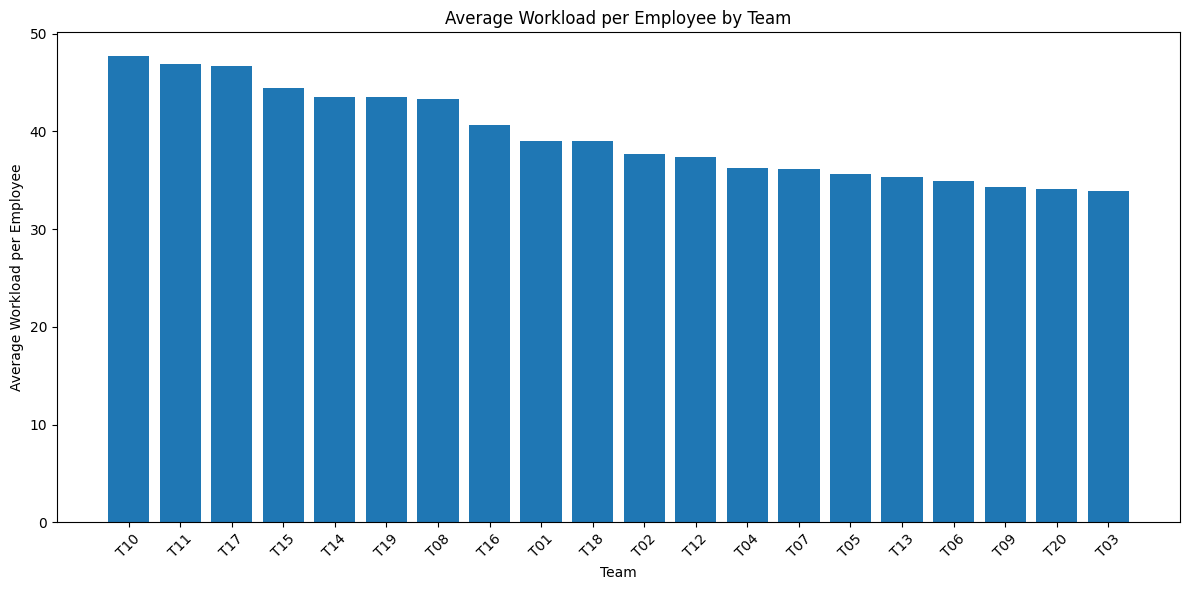

In [19]:
plt.figure(figsize=(12, 6))

plt.bar(
    team_summary["Team_ID"],
    team_summary["Workload_Per_Employee"]
)

plt.xlabel("Team")
plt.ylabel("Average Workload per Employee")
plt.title("Average Workload per Employee by Team")

plt.xticks(rotation=45)

plt.tight_layout()
plt.show()

In [20]:
print(
    team_summary[
        ["Team_ID", "Workload_Per_Employee",
         "Overtime", "Satisfaction_Score",
         "Project_Delivery"]
    ].head(10)
)

   Team_ID  Workload_Per_Employee    Overtime  Satisfaction_Score  \
9      T10              47.759821  107.200000            7.611429   
10     T11              46.921659  101.285714            7.664286   
16     T17              46.724206   98.416667            7.925000   
14     T15              44.430396   78.551724            7.927586   
13     T14              43.573477   68.483871            8.277419   
18     T19              43.480287   68.612903            8.145161   
7      T08              43.318182   65.631579            8.173684   
15     T16              40.675429   55.971429            8.531429   
0      T01              39.023704   47.703704            8.662963   
17     T18              39.019444   45.416667            8.583333   

    Project_Delivery  
9          87.934286  
10         89.585714  
16         88.911111  
14         91.493103  
13         93.483871  
18         91.658065  
7          91.868421  
15         92.282857  
0          94.174074  
17        

In [21]:
correlation = df["Overtime"].corr(
    df["Project_Delivery"]
)

print("Correlation:", correlation)

Correlation: -0.71653749413551


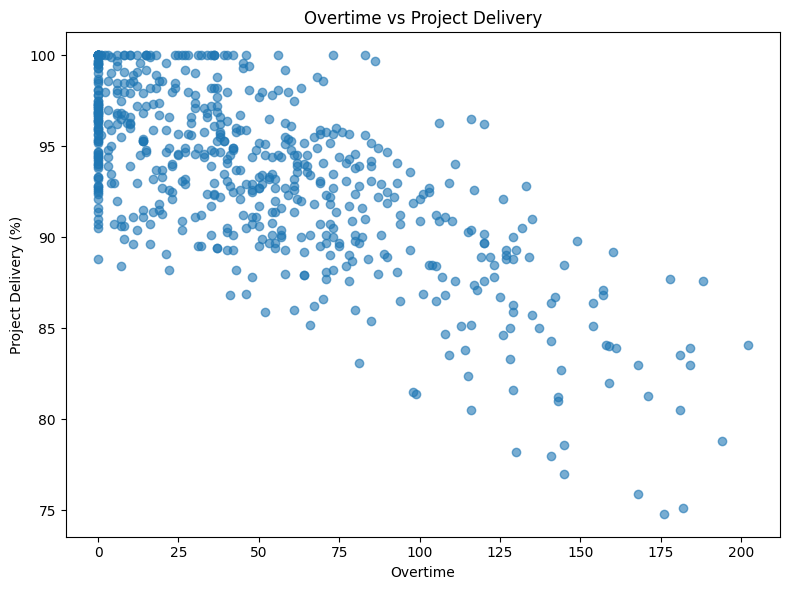

In [22]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Overtime"],
    df["Project_Delivery"],
    alpha=0.6
)

plt.xlabel("Overtime")
plt.ylabel("Project Delivery (%)")
plt.title("Overtime vs Project Delivery")

plt.tight_layout()
plt.show()

In [23]:
correlation = df["Workload_Per_Employee"].corr(
    df["Satisfaction_Score"]
)

print("Correlation:", correlation)


Correlation: -0.7860964553476043


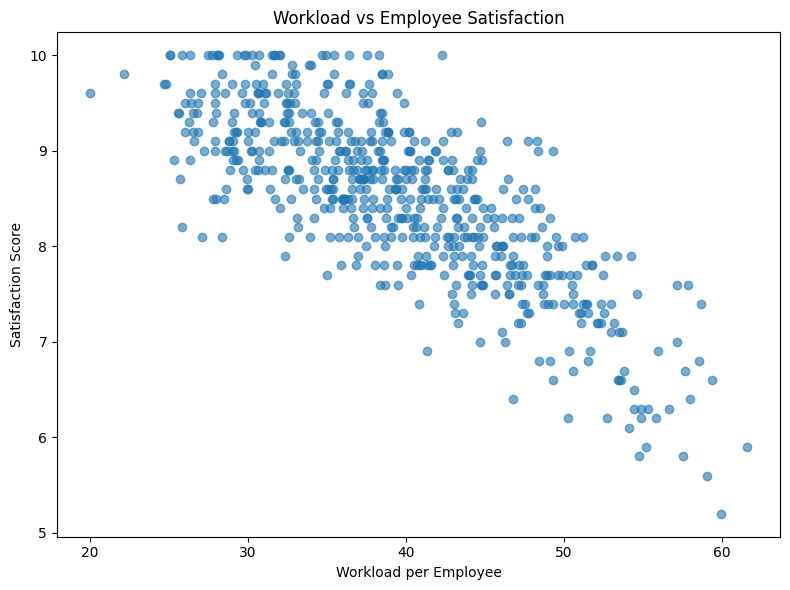

In [24]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Workload_Per_Employee"],
    df["Satisfaction_Score"],
    alpha=0.6
)

plt.xlabel("Workload per Employee")
plt.ylabel("Satisfaction Score")
plt.title("Workload vs Employee Satisfaction")

plt.tight_layout()
plt.show()

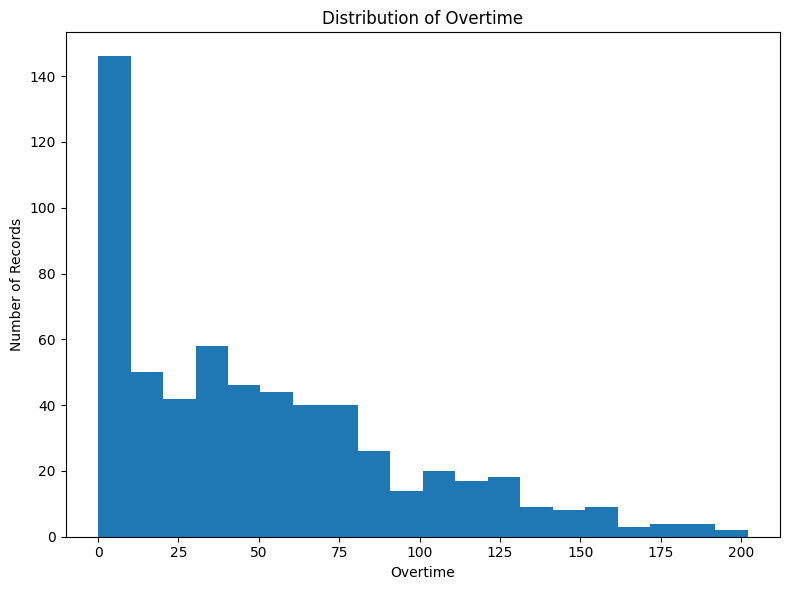

In [25]:
plt.figure(figsize=(8, 6))

plt.hist(
    df["Overtime"],
    bins=20
)

plt.xlabel("Overtime")
plt.ylabel("Number of Records")
plt.title("Distribution of Overtime")

plt.tight_layout()
plt.show()

In [26]:
print(team_summary.head(10))

   Team_ID  Workload_Per_Employee    Overtime  Satisfaction_Score  \
9      T10              47.759821  107.200000            7.611429   
10     T11              46.921659  101.285714            7.664286   
16     T17              46.724206   98.416667            7.925000   
14     T15              44.430396   78.551724            7.927586   
13     T14              43.573477   68.483871            8.277419   
18     T19              43.480287   68.612903            8.145161   
7      T08              43.318182   65.631579            8.173684   
15     T16              40.675429   55.971429            8.531429   
0      T01              39.023704   47.703704            8.662963   
17     T18              39.019444   45.416667            8.583333   

    Project_Delivery  
9          87.934286  
10         89.585714  
16         88.911111  
14         91.493103  
13         93.483871  
18         91.658065  
7          91.868421  
15         92.282857  
0          94.174074  
17        

In [27]:
print("Overtime vs Delivery:",
      df["Overtime"].corr(df["Project_Delivery"]))

Overtime vs Delivery: -0.71653749413551


In [28]:
print("Overtime vs Delivery:",
      df["Overtime"].corr(df["Project_Delivery"]))

Overtime vs Delivery: -0.71653749413551


In [29]:
print(
    "Workload vs Satisfaction:",
    df["Workload_Per_Employee"].corr(
        df["Satisfaction_Score"]
    )
)

Workload vs Satisfaction: -0.7860964553476043


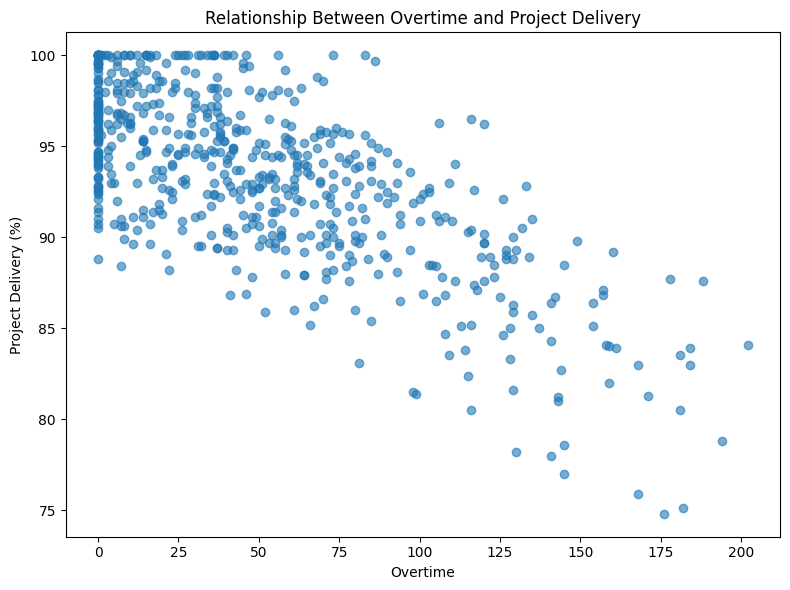

In [30]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Overtime"],
    df["Project_Delivery"],
    alpha=0.6
)

plt.xlabel("Overtime")
plt.ylabel("Project Delivery (%)")
plt.title("Relationship Between Overtime and Project Delivery")

plt.tight_layout()
plt.show()

In [31]:
workload_satisfaction_corr = df["Workload_Per_Employee"].corr(
    df["Satisfaction_Score"]
)

print(
    "Workload vs Satisfaction:",
    workload_satisfaction_corr
)

Workload vs Satisfaction: -0.7860964553476043


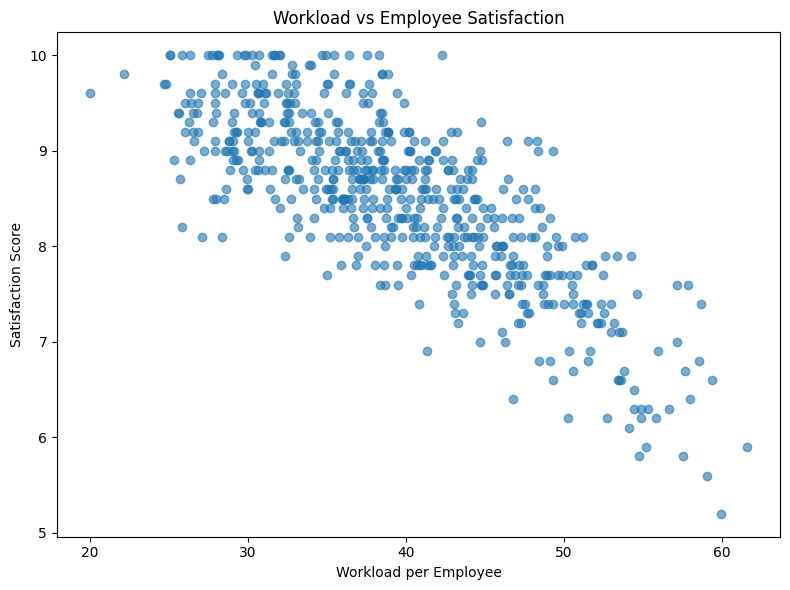

In [32]:
plt.figure(figsize=(8, 6))

plt.scatter(
    df["Workload_Per_Employee"],
    df["Satisfaction_Score"],
    alpha=0.6
)

plt.xlabel("Workload per Employee")
plt.ylabel("Satisfaction Score")
plt.title("Workload vs Employee Satisfaction")

plt.tight_layout()
plt.show()

In [33]:
team_summary["Workload_Rank"] = (
    team_summary["Workload_Per_Employee"].rank(
        ascending=False
    )
)

team_summary["Overtime_Rank"] = (
    team_summary["Overtime"].rank(
        ascending=False
    )
)

print(
    team_summary.sort_values(
        "Workload_Per_Employee",
        ascending=False
    ).head(10)
)

   Team_ID  Workload_Per_Employee    Overtime  Satisfaction_Score  \
9      T10              47.759821  107.200000            7.611429   
10     T11              46.921659  101.285714            7.664286   
16     T17              46.724206   98.416667            7.925000   
14     T15              44.430396   78.551724            7.927586   
13     T14              43.573477   68.483871            8.277419   
18     T19              43.480287   68.612903            8.145161   
7      T08              43.318182   65.631579            8.173684   
15     T16              40.675429   55.971429            8.531429   
0      T01              39.023704   47.703704            8.662963   
17     T18              39.019444   45.416667            8.583333   

    Project_Delivery  Workload_Rank  Overtime_Rank  
9          87.934286            1.0            1.0  
10         89.585714            2.0            2.0  
16         88.911111            3.0            3.0  
14         91.493103        

In [34]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

team_summary[
    [
        "Workload_Per_Employee",
        "Overtime",
        "Satisfaction_Score",
        "Project_Delivery"
    ]
] = scaler.fit_transform(
    team_summary[
        [
            "Workload_Per_Employee",
            "Overtime",
            "Satisfaction_Score",
            "Project_Delivery"
        ]
    ]
)

In [36]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

team_summary[
    [
        "Workload_Norm",
        "Overtime_Norm",
        "Satisfaction_Norm",
        "Delivery_Norm"
    ]
] = scaler.fit_transform(
    team_summary[
        [
            "Workload_Per_Employee",
            "Overtime",
            "Satisfaction_Score",
            "Project_Delivery"
        ]
    ]
)

print(team_summary.head())

   Team_ID  Workload_Per_Employee  Overtime  Satisfaction_Score  \
9      T10               1.000000  1.000000            0.000000   
10     T11               0.939574  0.931367            0.034884   
16     T17               0.925339  0.898073            0.206945   
14     T15               0.759969  0.667549            0.208652   
13     T14               0.698191  0.550716            0.439529   

    Project_Delivery  Workload_Rank  Overtime_Rank  Workload_Norm  \
9           0.000000            1.0            1.0       1.000000   
10          0.203625            2.0            2.0       0.939574   
16          0.120445            3.0            3.0       0.925339   
14          0.438810            4.0            4.0       0.759969   
13          0.684276            5.0            6.0       0.698191   

    Overtime_Norm  Satisfaction_Norm  Delivery_Norm  
9        1.000000           0.000000       0.000000  
10       0.931367           0.034884       0.203625  
16       0.898073   

In [39]:
team_summary["Workload_Pressure_Score"] = (
    0.30 * team_summary["Workload_Norm"]
    + 0.30 * team_summary["Overtime_Norm"]
    + 0.20 * (1 - team_summary["Satisfaction_Norm"])
    + 0.20 * (1 - team_summary["Delivery_Norm"])
)

In [38]:
team_summary = team_summary.sort_values(
    "Workload_Pressure_Score",
    ascending=False
)

print(
    team_summary[
        [
            "Team_ID",
            "Workload_Per_Employee",
            "Overtime",
            "Satisfaction_Score",
            "Project_Delivery",
            "Workload_Pressure_Score"
        ]
    ].head(10)
)

   Team_ID  Workload_Per_Employee  Overtime  Satisfaction_Score  \
9      T10               1.000000  1.000000            0.000000   
10     T11               0.939574  0.931367            0.034884   
16     T17               0.925339  0.898073            0.206945   
14     T15               0.759969  0.667549            0.208652   
18     T19               0.691472  0.552213            0.352243   
7      T08               0.679785  0.517616            0.371068   
13     T14               0.698191  0.550716            0.439529   
15     T16               0.489259  0.405515            0.607165   
17     T18               0.369873  0.283031            0.641420   
0      T01               0.370180  0.309571            0.693973   

    Project_Delivery  Workload_Pressure_Score  
9           0.000000                 1.000000  
10          0.203625                 0.913581  
16          0.120445                 0.881546  
14          0.438810                 0.698763  
18          0.459150  

In [40]:
team_summary = df.groupby("Team_ID").agg({
    "Workload_Per_Employee": "mean",
    "Overtime": "mean",
    "Satisfaction_Score": "mean",
    "Project_Delivery": "mean"
}).reset_index()

print(team_summary.head())

  Team_ID  Workload_Per_Employee   Overtime  Satisfaction_Score  \
0     T01              39.023704  47.703704            8.662963   
1     T02              37.672414  31.500000            8.493333   
2     T03              33.888996  21.027027            8.913514   
3     T04              36.231169  32.142857            8.720000   
4     T05              35.688640  31.000000            8.791304   

   Project_Delivery  
0         94.174074  
1         95.410000  
2         95.429730  
3         94.348571  
4         94.791304  


In [41]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

team_summary[
    [
        "Workload_Norm",
        "Overtime_Norm",
        "Satisfaction_Norm",
        "Delivery_Norm"
    ]
] = scaler.fit_transform(
    team_summary[
        [
            "Workload_Per_Employee",
            "Overtime",
            "Satisfaction_Score",
            "Project_Delivery"
        ]
    ]
)

In [42]:
team_summary["Workload_Pressure_Score"] = (
    0.30 * team_summary["Workload_Norm"]
    + 0.30 * team_summary["Overtime_Norm"]
    + 0.20 * (1 - team_summary["Satisfaction_Norm"])
    + 0.20 * (1 - team_summary["Delivery_Norm"])
)

In [43]:
team_summary = team_summary.sort_values(
    "Workload_Pressure_Score",
    ascending=False
)

In [44]:
print(
    team_summary[
        [
            "Team_ID",
            "Workload_Per_Employee",
            "Overtime",
            "Satisfaction_Score",
            "Project_Delivery",
            "Workload_Pressure_Score"
        ]
    ].head(10)
)

   Team_ID  Workload_Per_Employee    Overtime  Satisfaction_Score  \
9      T10              47.759821  107.200000            7.611429   
10     T11              46.921659  101.285714            7.664286   
16     T17              46.724206   98.416667            7.925000   
14     T15              44.430396   78.551724            7.927586   
18     T19              43.480287   68.612903            8.145161   
7      T08              43.318182   65.631579            8.173684   
13     T14              43.573477   68.483871            8.277419   
15     T16              40.675429   55.971429            8.531429   
17     T18              39.019444   45.416667            8.583333   
0      T01              39.023704   47.703704            8.662963   

    Project_Delivery  Workload_Pressure_Score  
9          87.934286                 1.000000  
10         89.585714                 0.913581  
16         88.911111                 0.881546  
14         91.493103                 0.698763  


In [45]:
print(
    team_summary[
        [
            "Team_ID",
            "Workload_Per_Employee",
            "Overtime",
            "Satisfaction_Score",
            "Project_Delivery",
            "Workload_Pressure_Score"
        ]
    ].head(10)
)

   Team_ID  Workload_Per_Employee    Overtime  Satisfaction_Score  \
9      T10              47.759821  107.200000            7.611429   
10     T11              46.921659  101.285714            7.664286   
16     T17              46.724206   98.416667            7.925000   
14     T15              44.430396   78.551724            7.927586   
18     T19              43.480287   68.612903            8.145161   
7      T08              43.318182   65.631579            8.173684   
13     T14              43.573477   68.483871            8.277419   
15     T16              40.675429   55.971429            8.531429   
17     T18              39.019444   45.416667            8.583333   
0      T01              39.023704   47.703704            8.662963   

    Project_Delivery  Workload_Pressure_Score  
9          87.934286                 1.000000  
10         89.585714                 0.913581  
16         88.911111                 0.881546  
14         91.493103                 0.698763  


In [46]:
# Create a copy for weekly workload analysis
weekly_df = df.copy()

# Assign sequential weeks within each team
weekly_df["Week"] = weekly_df.groupby("Team_ID").cumcount() + 1

print(weekly_df[
    ["Team_ID", "Week", "Workload_Per_Employee"]
].head(20))

   Team_ID  Week  Workload_Per_Employee
0      T06     1              43.043478
1      T11     1              56.645161
2      T05     1              43.935484
3      T05     2              41.387097
4      T04     1              47.272727
5      T09     1              30.028571
6      T11     2              38.645161
7      T19     1              51.444444
8      T12     1              32.500000
9      T04     2              27.909091
10     T01     1              46.720000
11     T05     3              27.741935
12     T15     1              48.925926
13     T17     1              42.857143
14     T16     1              38.600000
15     T10     1              51.375000
16     T10     2              59.031250
17     T16     2              51.760000
18     T10     3              44.593750
19     T02     1              30.689655


In [47]:
weekly_workload = weekly_df.groupby(
    ["Team_ID", "Week"]
)["Workload_Per_Employee"].mean().reset_index()

print(weekly_workload.head(20))

   Team_ID  Week  Workload_Per_Employee
0      T01     1                  46.72
1      T01     2                  40.44
2      T01     3                  28.36
3      T01     4                  41.36
4      T01     5                  47.40
5      T01     6                  48.20
6      T01     7                  37.72
7      T01     8                  26.52
8      T01     9                  46.76
9      T01    10                  49.00
10     T01    11                  29.76
11     T01    12                  34.72
12     T01    13                  43.32
13     T01    14                  39.68
14     T01    15                  43.28
15     T01    16                  27.24
16     T01    17                  47.76
17     T01    18                  44.32
18     T01    19                  33.72
19     T01    20                  38.52


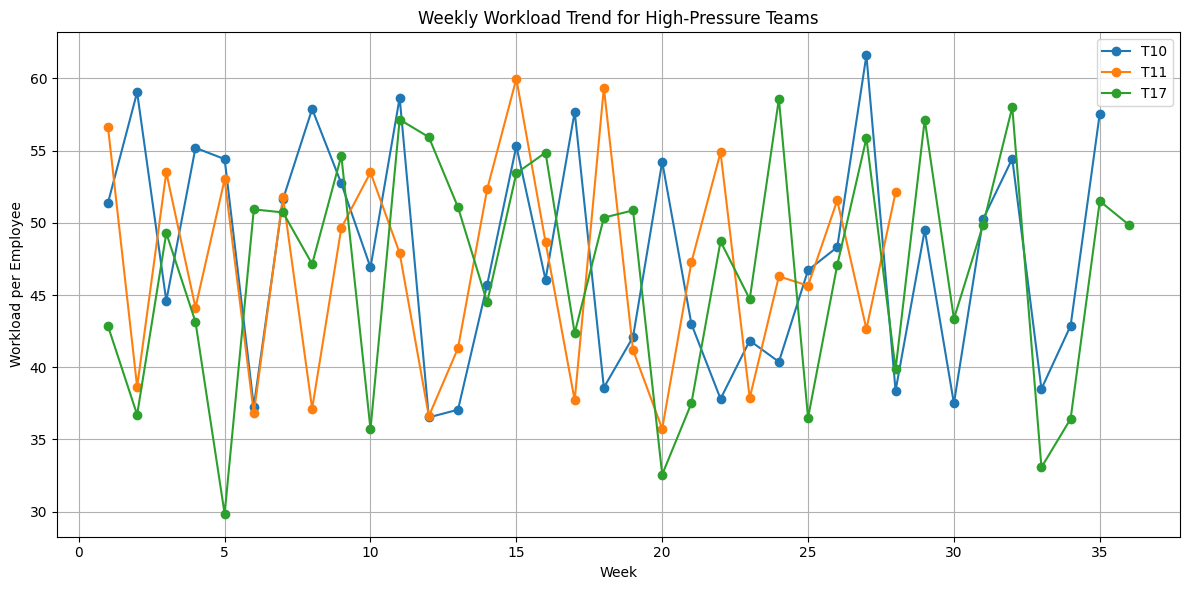

In [48]:
top_teams = ["T10", "T11", "T17"]

trend_data = weekly_workload[
    weekly_workload["Team_ID"].isin(top_teams)
]

plt.figure(figsize=(12, 6))

for team in top_teams:
    team_data = trend_data[
        trend_data["Team_ID"] == team
    ]

    plt.plot(
        team_data["Week"],
        team_data["Workload_Per_Employee"],
        marker="o",
        label=team
    )

plt.xlabel("Week")
plt.ylabel("Workload per Employee")
plt.title("Weekly Workload Trend for High-Pressure Teams")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [49]:
workload_threshold = df["Workload_Per_Employee"].quantile(0.75)
overtime_threshold = df["Overtime"].quantile(0.75)

print("Workload threshold:", workload_threshold)
print("Overtime threshold:", overtime_threshold)

Workload threshold: 44.78703703703704
Overtime threshold: 76.25


In [50]:
df["Overload_Status"] = (
    (df["Workload_Per_Employee"] >= workload_threshold) &
    (df["Overtime"] >= overtime_threshold)
).astype(int)

In [51]:
print(df["Overload_Status"].value_counts())

Overload_Status
0    474
1    126
Name: count, dtype: int64


In [52]:
features = [
    "Project_Hours",
    "Employee_Count",
    "Overtime",
    "Leave",
    "Deadlines",
    "Project_Delivery",
    "Satisfaction_Score",
    "Workload_Per_Employee"
]

X = df[features]
y = df["Overload_Status"]

In [53]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 480
Testing samples: 120


In [54]:
from sklearn.ensemble import RandomForestClassifier

model = RandomForestClassifier(
    n_estimators=100,
    random_state=42
)

model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [55]:
y_pred = model.predict(X_test)

In [56]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

accuracy = accuracy_score(y_test, y_pred)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)

print("Accuracy :", accuracy)
print("Precision:", precision)
print("Recall   :", recall)
print("F1 Score :", f1)

Accuracy : 0.9916666666666667
Precision: 1.0
Recall   : 0.96
F1 Score : 0.9795918367346939


In [57]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

                 Feature  Importance
2               Overtime    0.409456
7  Workload_Per_Employee    0.293695
4              Deadlines    0.094087
6     Satisfaction_Score    0.068562
5       Project_Delivery    0.063351
0          Project_Hours    0.045974
1         Employee_Count    0.013329
3                  Leave    0.011547


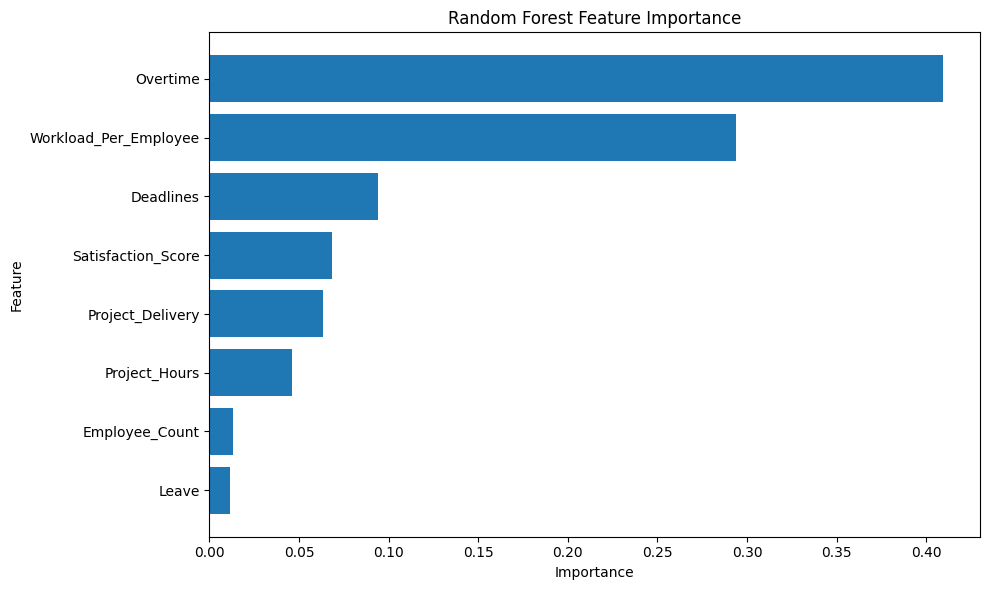

In [58]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

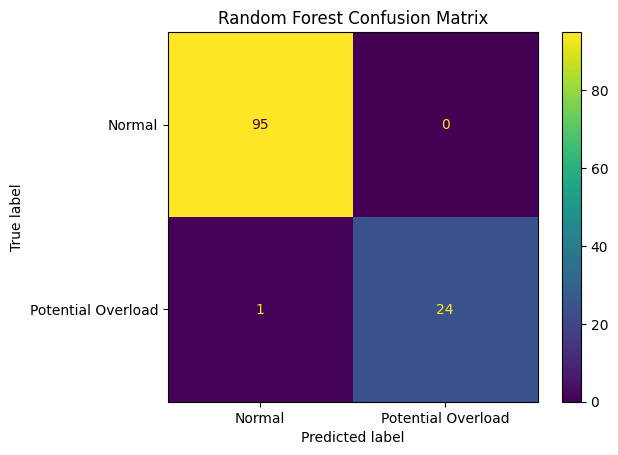

In [59]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Normal", "Potential Overload"]
)

disp.plot()
plt.title("Random Forest Confusion Matrix")
plt.show()

In [60]:
importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    "Importance",
    ascending=False
)

print(importance)

                 Feature  Importance
2               Overtime    0.409456
7  Workload_Per_Employee    0.293695
4              Deadlines    0.094087
6     Satisfaction_Score    0.068562
5       Project_Delivery    0.063351
0          Project_Hours    0.045974
1         Employee_Count    0.013329
3                  Leave    0.011547


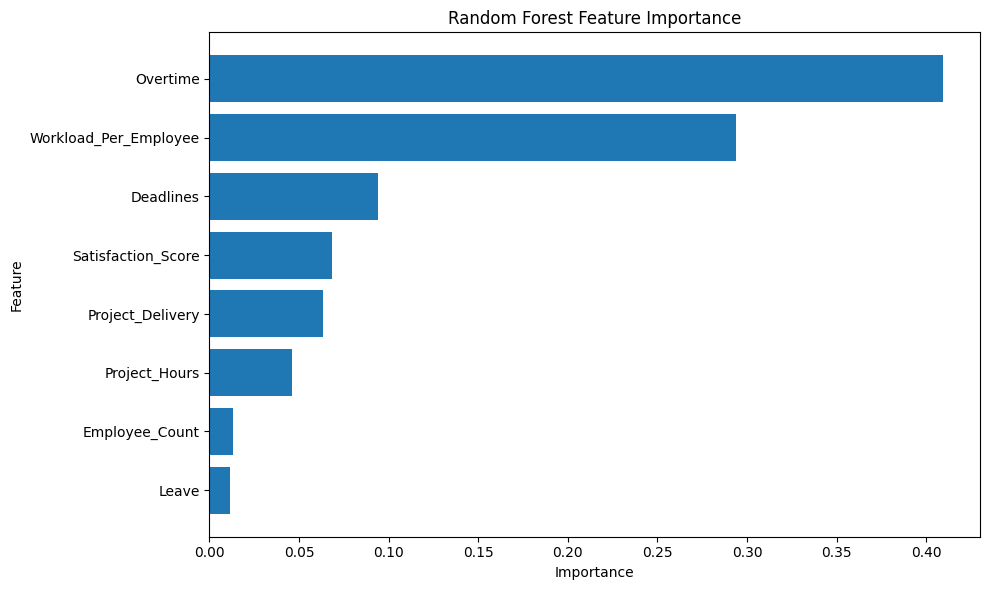

In [61]:
plt.figure(figsize=(10, 6))

plt.barh(
    importance["Feature"],
    importance["Importance"]
)

plt.xlabel("Importance")
plt.ylabel("Feature")
plt.title("Random Forest Feature Importance")

plt.gca().invert_yaxis()

plt.tight_layout()
plt.show()

In [62]:
print("Model Evaluation")
print("----------------")
print(f"Accuracy : {accuracy:.4f}")
print(f"Precision: {precision:.4f}")
print(f"Recall   : {recall:.4f}")
print(f"F1 Score : {f1:.4f}")

Model Evaluation
----------------
Accuracy : 0.9917
Precision: 1.0000
Recall   : 0.9600
F1 Score : 0.9796
